# Step 6: El Niño case module, explainability layers, alert prototype, comparison table, compliance audit
Run Steps 1 to 5 first. Needs the raw folders `2. Enso`, `3. Brent...`, `5. NY Fed` and the saved CSV outputs of Steps 1 to 5 in `MyDrive/Dataset`. Runtime: a few minutes.

In [1]:
!pip install -q xlrd
import pandas as pd, numpy as np
from google.colab import drive
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/My Work/Research/AI+ BBA/Supply Chain_GNN/Dataset'

Mounted at /content/drive


## 1. Setup, data audit and data dictionary (table 1)

In [2]:
import statsmodels.api as sm, matplotlib.pyplot as plt, glob, os, warnings
from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
rng = np.random.default_rng(7)
ACCESS_DATE = "2026-10-24"

panel = pd.read_csv(f"{BASE}/monthly_panel_with_hormuz_state.csv")
panel["month"] = pd.PeriodIndex(panel["month"], freq="M"); panel = panel.set_index("month").sort_index().loc[:"2026-09"]

enso = pd.read_csv(f"{BASE}/2. Enso/dataset_enso_2026.csv", encoding="latin-1"); enso.columns = [c.strip() for c in enso.columns]
enso["month"] = pd.to_datetime(enso["Date"], format="%m/%d/%Y").dt.to_period("M"); enso = enso.set_index("month")
br = pd.read_csv(f"{BASE}/3. Brent and WTI spot prices from EIA/brent-monthly.csv"); br["month"] = pd.to_datetime(br["Date"]).dt.to_period("M")
lb_full = np.log(br.set_index("month")["Price"])
g_ = pd.read_excel(f"{BASE}/5. NY Fed/gscpi_data.xls", sheet_name="GSCPI Monthly Data").iloc[:, :2]; g_.columns = ["d", "v"]; g_ = g_.dropna()
gs_full = g_.assign(month=pd.to_datetime(g_["d"], format="%d-%b-%Y").dt.to_period("M")).set_index("month")["v"]

# --- leakage audit: recompute every feature using ONLY data up to t and compare with the stored panel value
def feats_at(t):
    s = panel.loc[:t]
    return {"brent_ret1": s.brent.pct_change(1).iloc[-1], "brent_ret3": s.brent.pct_change(3).iloc[-1],
            "brent_z12": ((s.brent - s.brent.rolling(12).mean()) / s.brent.rolling(12).std()).iloc[-1],
            "oni_lag1": s.oni.shift(1).iloc[-1], "oni_chg3": s.oni.diff(3).shift(1).iloc[-1],
            "nino34_lag1": s.nino34_anom.shift(1).iloc[-1], "gscpi_lag1": s.gscpi.shift(1).iloc[-1], "gscpi_chg3": s.gscpi.diff(3).iloc[-1]}
checks = rng.choice(panel.loc["2003-01":"2026-06"].index, 40, replace=False); bad = 0
for t in checks:
    for k, v in feats_at(t).items():
        if not np.isclose(v, panel.loc[t, k], equal_nan=True): bad += 1
print(f"LEAKAGE AUDIT: {len(checks)} random months x 8 features recomputed from data <= t; mismatches = {bad}")

def cov(s):
    s = s.dropna(); return (str(s.index.min())[:10], str(s.index.max())[:10], len(s))
rows = [
 ("oni", "Oceanic Nino Index (3-month mean of Nino-3.4 anomaly)", "deg C", "monthly", "2. Enso/dataset_enso_2026.csv", "NOAA CPC https://www.cpc.ncep.noaa.gov/data/indices/", "El Nino driver", "CPC moved to RONI for official monitoring in 2026; file ends Apr 2026", cov(enso["ONI"])),
 ("roni", "Relative ONI (tropical-mean adjusted)", "deg C", "monthly", "2. Enso/dataset_enso_2026.csv", "NOAA CPC RONI page", "El Nino driver (official index since 2026)", "Differs strongly from ONI in 2026 (Apr: ONI +0.48, RONI -0.24)", cov(enso["RONI"])),
 ("nino34_anom", "Nino-3.4 SST anomaly", "deg C", "monthly", "2. Enso/dataset_enso_2026.csv", "NOAA CPC", "El Nino driver", "Ends May 2026 in the file", cov(enso["Nino 3.4 SST Anomaly"])),
 ("brent", "Brent spot price, monthly average", "USD/bbl", "monthly", "3. Brent.../brent-monthly.csv", "EIA via DataHub https://datahub.io/core/oil-prices", "Hormuz mediator / outcome", "Third-party redistribution of EIA series; check revisions", cov(panel["brent"])),
 ("gscpi", "Global Supply Chain Pressure Index", "SD units", "monthly", "5. NY Fed/gscpi_data.xls", "NY Fed GSCPI", "Operational stress / outcome proxy", "Global index, not node-level; historical values are revised", cov(panel["gscpi"])),
 ("hz_transits", "Mean daily Hormuz transit calls (AIS)", "ships/day", "daily -> monthly", "1. IMF Hormuz/straits-transits.csv", "IMF PortWatch (via straits.live redistribution)", "Hormuz mediator", "Starts 2025-02-28; AIS gaps after Feb 2026; cite PortWatch, verify values", cov(panel["hz_transits"])),
 ("hz_state_mode", "Hormuz state 0-4 (dominant state in month)", "category", "daily -> monthly", "step 2 output", "Authors' coding rule (50%/20% of baseline throughput)", "Hormuz shock state", "State 1 not coded; thresholds are authors' choice (see sensitivity)", cov(panel["hz_state_mode"])),
 ("y_gscpi_h3", "GSCPI rises >= 0.5 SD within 3 months", "0/1", "monthly", "step 1 output", "Authors' definition", "Final target (proxy)", "Global proxy of disruption", cov(panel["y_gscpi_h3"])),
 ("y_brent_h3", "Brent rises >= 10% within 3 months", "0/1", "monthly", "step 1 output", "Authors' definition", "Final target (price channel)", "Price proxy, not a physical shortage", cov(panel["y_brent_h3"]))]
dd = pd.DataFrame([dict(variable=r[0], definition=r[1], unit=r[2], frequency=r[3], file=r[4], publisher_or_url=r[5], causal_role=r[6], caveat=r[7],
                        first_obs=r[8][0], last_obs=r[8][1], n_obs=r[8][2], access_date=ACCESS_DATE) for r in rows])
dd["missing_rule"] = "kept as missing (no zero-fill); models impute with training median or handle NaN natively"
print(dd[["variable", "frequency", "first_obs", "last_obs", "n_obs"]].to_string(index=False)); dd.to_csv(f"{BASE}/table1_data_dictionary.csv", index=False)

LEAKAGE AUDIT: 40 random months x 8 features recomputed from data <= t; mismatches = 0
     variable        frequency first_obs last_obs  n_obs
          oni          monthly   1950-01  2026-04    916
         roni          monthly   1950-01  2026-04    916
  nino34_anom          monthly   1950-01  2026-05    917
        brent          monthly   1998-01  2026-09    345
        gscpi          monthly   1998-01  2026-09    345
  hz_transits daily -> monthly   2025-02  2026-09     20
hz_state_mode daily -> monthly   2025-03  2026-09     19
   y_gscpi_h3          monthly   1998-01  2026-06    342
   y_brent_h3          monthly   1998-01  2026-06    342


## 2. El nino case: historical episodes and composite event study

  onset     end  months  peak_oni    strength  overlaps_covid
1991-06 1992-06      13      1.71      strong           False
1994-09 1995-03       7      1.09    moderate           False
1997-05 1998-04      12      2.40 very strong           False
2002-06 2003-02       9      1.31    moderate           False
2004-08 2005-02       7      0.70        weak           False
2006-09 2007-01       5      0.94        weak           False
2009-08 2010-03       8      1.56      strong           False
2014-10 2016-04      19      2.75 very strong           False
2018-09 2019-06      10      0.97        weak           False
2019-11 2020-03       5      0.66        weak            True
2023-05 2024-04      12      2.06 very strong           False
              series  n_episodes  mean_change_6m_after_onset  null_mean  null_sd  p_two_sided leave_one_out_range  mean_excluding_covid_episode
  Brent (log change)          11                      -0.082      0.023    0.078        0.178      [-0.11, -0.01

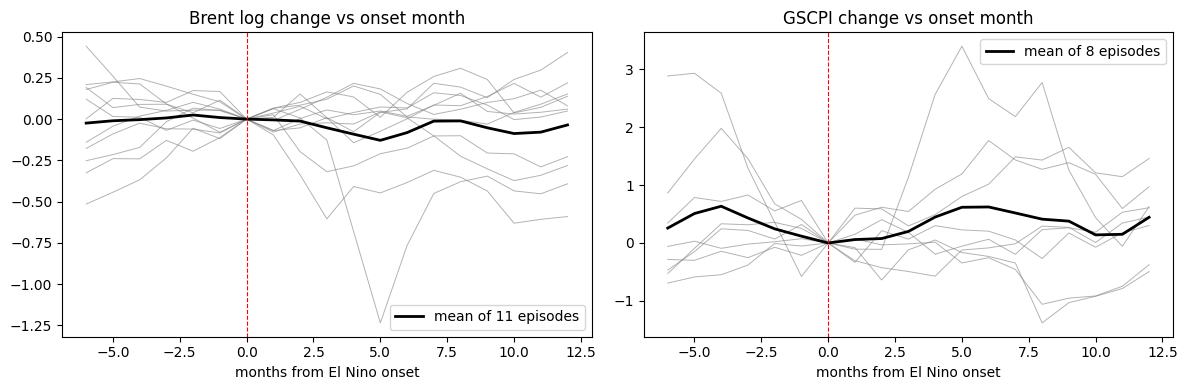

            outcome                 regressor   coef     p   n  p_holm
Brent 3m log change El Nino active (ONI>=0.5) -0.057 0.152 321   0.456
Brent 3m log change               ONI (lag 1) -0.040 0.047 321   0.188
    GSCPI 3m change El Nino active (ONI>=0.5)  0.178 0.168 321   0.456
    GSCPI 3m change               ONI (lag 1)  0.062 0.333 321   0.456


In [3]:
oni_s = enso["ONI"].dropna(); warm = (oni_s >= 0.5).astype(int); grp = (warm != warm.shift()).cumsum()
cls = lambda x: "very strong" if x >= 2.0 else "strong" if x >= 1.5 else "moderate" if x >= 1.0 else "weak"
eps = pd.DataFrame([dict(onset=g.index[0], end=g.index[-1], months=len(g), peak_oni=round(g.max(), 2), strength=cls(g.max()))
                    for k, g in oni_s.groupby(grp) if (g >= 0.5).all() and len(g) >= 5])
eps = eps[eps.onset >= pd.Period("1987-01", freq="M")].reset_index(drop=True)
eps["overlaps_covid"] = eps["onset"].astype(str).isin(["2019-11"])           # onset Nov 2019: the following months overlap the COVID shock
print(eps.assign(onset=eps.onset.astype(str), end=eps.end.astype(str)).to_string(index=False))
eps.assign(onset=eps.onset.astype(str), end=eps.end.astype(str)).to_csv(f"{BASE}/table_elnino_episodes.csv", index=False)

def composite_test(series, first, w=6, draws=3000):
    ons = [o for o in eps.onset if o >= pd.Period(first, freq="M") and (o + w) in series.index and o in series.index]
    obs = {o: float(series.loc[o + w] - series.loc[o]) for o in ons}
    pool = [m for m in series.index if m >= pd.Period(first, freq="M") and (m + w) in series.index and m <= pd.Period("2025-12", freq="M")]
    dser = pd.Series({m: float(series.loc[m + w] - series.loc[m]) for m in pool})
    v = np.array(list(obs.values())); null = np.array([dser.sample(len(v), random_state=int(rng.integers(1e9))).mean() for _ in range(draws)])
    p2 = float((np.abs(null - null.mean()) >= abs(v.mean() - null.mean())).mean())
    loo = [np.delete(v, i).mean() for i in range(len(v))]
    ex_covid = np.mean([x for o, x in obs.items() if str(o) != "2019-11"])
    return dict(n_episodes=len(v), mean_change_6m_after_onset=round(v.mean(), 3), null_mean=round(null.mean(), 3), null_sd=round(null.std(), 3),
                p_two_sided=round(p2, 3), leave_one_out_range=f"[{min(loo):.2f}, {max(loo):.2f}]", mean_excluding_covid_episode=round(float(ex_covid), 3)), obs
ct_b, obs_b = composite_test(lb_full, "1988-01"); ct_g, obs_g = composite_test(gs_full, "1998-07")
comp = pd.DataFrame([dict(series="Brent (log change)", **ct_b), dict(series="GSCPI (level change)", **ct_g)]); print(comp.to_string(index=False)); comp.to_csv(f"{BASE}/table_elnino_composite.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 4)); ks = list(range(-6, 13))
for ax, (nm, s, first) in zip(axs, [("Brent log change vs onset month", lb_full, "1988-01"), ("GSCPI change vs onset month", gs_full, "1998-07")]):
    M = []
    for o in eps.onset:
        if o >= pd.Period(first, freq="M") and all((o + k) in s.index for k in ks):
            row = [float(s.loc[o + k] - s.loc[o]) for k in ks]; M.append(row); ax.plot(ks, row, color="grey", lw=0.7, alpha=0.6)
    M = np.array(M); ax.plot(ks, M.mean(0), "k-", lw=2, label=f"mean of {len(M)} episodes"); ax.axvline(0, color="r", ls="--", lw=0.8)
    ax.set_title(nm); ax.set_xlabel("months from El Nino onset"); ax.legend()
fig.tight_layout(); fig.savefig(f"{BASE}/fig_elnino_composite.png", dpi=150); plt.show()

# phase regressions (exploratory, Holm-corrected over the 4 tests)
d = pd.DataFrame({"lb": lb_full, "g": gs_full}).join(enso["ONI"].rename("oni")); d["db"] = d.lb.diff(); d["dg"] = d.g.diff()
d["y_b"] = d.lb.shift(-3) - d.lb; d["y_g"] = d.g.shift(-3) - d.g; d["oni_l1"] = d.oni.shift(1); d["warm"] = (d.oni_l1 >= 0.5).astype(float)
reg = []
for y in ("y_b", "y_g"):
    s = d.loc["1999-01":"2025-09"].dropna(subset=[y, "warm", "oni_l1", "db", "dg"])
    for x in ("warm", "oni_l1"):
        m = sm.OLS(s[y], sm.add_constant(s[[x, "db", "dg"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
        reg.append(dict(outcome="Brent 3m log change" if y == "y_b" else "GSCPI 3m change", regressor="El Nino active (ONI>=0.5)" if x == "warm" else "ONI (lag 1)",
                        coef=round(m.params[x], 3), p=round(m.pvalues[x], 3), n=len(s)))
reg = pd.DataFrame(reg); o = reg.p.rank(method="first").astype(int).sort_values(); run = 0; hol = {}
for i, ix in enumerate(o.index): run = max(run, min(1, (len(reg) - i) * reg.p[ix])); hol[ix] = run
reg["p_holm"] = pd.Series(hol).round(3); print(reg.to_string(index=False)); reg.to_csv(f"{BASE}/table_elnino_phase_regression.csv", index=False)

## 3. El nino 2026: forecast-vintage table (proposal section 8)

In [4]:
CPC = "https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso_advisory/ensodisc.shtml"
vint = pd.DataFrame([
 dict(issue_date="2026-03-12", alert_status="ENSO-neutral expected; El Nino likely to emerge Jun-Aug (62%)", p_very_strong=np.nan, p_historic=np.nan, observed="", source=CPC, source_type="CPC text as quoted by secondary page; verify in CPC archive"),
 dict(issue_date="2026-06-08", alert_status="El Nino likely to emerge (82% for May-Jul); 96% persists into winter 2026-27", p_very_strong=np.nan, p_historic=np.nan, observed="weekly Nino-3.4 about +0.7", source="https://cpc.ncep.noaa.gov/products/analysis_monitoring/lanina/enso_evolution-status-fcsts-web.pdf", source_type="CPC slide deck (primary)"),
 dict(issue_date="2026-06-11", alert_status="El Nino Advisory begins", p_very_strong=63, p_historic=np.nan, observed="", source=CPC, source_type="reported by secondary pages (The Inertia, CVF-V20); verify in CPC archive"),
 dict(issue_date="2026-07-09", alert_status="El Nino Advisory; 97% persists to early spring 2027", p_very_strong=81, p_historic=np.nan, observed="", source="https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso_disc_jul2026/ensodisc.shtml", source_type="CPC discussion (primary)"),
 dict(issue_date="2026-08-13", alert_status="El Nino Advisory; strengthening", p_very_strong=90, p_historic=69, observed="July Nino-3.4 +1.4 C", source="https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso_disc_aug2026/ensodisc.shtml", source_type="CPC discussion (primary); '>90%' stored as lower bound"),
 dict(issue_date="2026-09-10", alert_status="El Nino Advisory; strengthening", p_very_strong=90, p_historic=75, observed="Aug Nino-3.4 +1.8 C; Nino-3 +2.5; Nino-1+2 +3.4; Nino-4 +0.1", source=CPC, source_type="CPC discussion (primary); '>90%' stored as lower bound"),
 dict(issue_date="2026-10-08", alert_status="NOT RETRIEVED - fill from CPC archive", p_very_strong=np.nan, p_historic=np.nan, observed="", source=CPC, source_type="scheduled release; check")])
vint["access_date"] = ACCESS_DATE
vint["outcome_window"] = ["Oct-Dec 2026 (strong)", "winter 2026-27", "Oct-Dec 2026", "Oct-Dec 2026", "NH fall-winter 2026-27 (very strong); Oct-Dec (historic >= +2.5 RONI)", "same as Aug", ""]
print(vint[["issue_date", "alert_status", "p_very_strong", "p_historic"]].to_string(index=False)); vint.to_csv(f"{BASE}/table_elnino_2026_vintages.csv", index=False)

issue_date                                                                 alert_status  p_very_strong  p_historic
2026-03-12                ENSO-neutral expected; El Nino likely to emerge Jun-Aug (62%)            NaN         NaN
2026-06-08 El Nino likely to emerge (82% for May-Jul); 96% persists into winter 2026-27            NaN         NaN
2026-06-11                                                      El Nino Advisory begins           63.0         NaN
2026-07-09                          El Nino Advisory; 97% persists to early spring 2027           81.0         NaN
2026-08-13                                              El Nino Advisory; strengthening           90.0        69.0
2026-09-10                                              El Nino Advisory; strengthening           90.0        75.0
2026-10-08                                        NOT RETRIEVED - fill from CPC archive            NaN         NaN



## 4. Structural model, el nino scenarios (section 13) and path-specific explanation

In [5]:
D = pd.DataFrame({"g": panel["gscpi"], "lb": np.log(panel["brent"]), "oni": panel["oni"]})
D["dg"] = D.g.diff(); D["db"] = D.lb.diff(); D["oni_l1"] = D.oni.shift(1); D["dg_next"] = D.dg.shift(-1); D["db_next"] = D.db.shift(-1)
GC, BC = ["dg", "g", "db", "oni_l1"], ["db", "dg", "oni_l1"]
s_ = D.loc["1999-01":"2025-12"].dropna(subset=GC + ["dg_next", "db_next"])
mg = sm.OLS(s_.dg_next, sm.add_constant(s_[GC])).fit(); mb = sm.OLS(s_.db_next, sm.add_constant(s_[BC])).fit(); res = np.column_stack([mg.resid.values, mb.resid.values])
print("ENSO coefficient in GSCPI equation:", round(mg.params["oni_l1"], 3), "p =", round(mg.pvalues["oni_l1"], 3), "| in Brent equation:", round(mb.params["oni_l1"], 3), "p =", round(mb.pvalues["oni_l1"], 3))

def simulate(row, h, n=4000, oni_path=None, kill_brent=False, kill_enso=False, force_brent=None):
    idx = rng.integers(0, len(res), size=(n, h)); G = np.full(n, row["g"]); DG = np.full(n, row["dg"]); DB = np.full(n, row["db"]); LB = np.zeros(n); best = np.full(n, -np.inf)
    for k in range(h):
        o = (oni_path[k] if oni_path is not None else row["oni_l1"]); o = 0.0 if kill_enso else o; e = res[idx[:, k]]
        bco = 0.0 if kill_brent else mg.params["db"]
        dgn = mg.params["const"] + mg.params["dg"] * DG + mg.params["g"] * G + bco * DB + mg.params["oni_l1"] * o + e[:, 0]
        dbn = mb.params["const"] + mb.params["db"] * DB + mb.params["dg"] * DG + mb.params["oni_l1"] * o + e[:, 1]
        if force_brent is not None and k in force_brent: dbn = np.full(n, force_brent[k])
        G = G + dgn; LB = LB + dbn; DG, DB = dgn, dbn; best = np.maximum(best, G - row["g"])
    return best, np.exp(LB) - 1

ONI_NOW = 1.4        # ASSUMPTION: replace with the latest CPC ONI/RONI value (file stops Apr 2026; official Nino-3.4 was +1.4 in Jul, +1.8 in Aug)
r0 = D.loc[pd.Period("2026-09", freq="M")].copy(); r0["oni_l1"] = ONI_NOW
scn = {"Baseline (neutral reference, ONI 0)": [0, 0, 0], "Moderate (probable regional anomaly, ONI +1.0)": [1, 1, 1],
       "Severe (strong event, ONI +2.0)": [2, 2, 2], "Recovery (decay 2.0 -> 1.0 -> 0.3)": [2.0, 1.0, 0.3]}
rows = []
for nm, path in scn.items():
    best, bchg = simulate(r0, 3, oni_path=path); rows.append(dict(scenario=nm, P_gscpi_rise_ge_0_5_in_3m=round(float((best >= 0.5).mean()), 3), mean_brent_change_3m_pct=round(float(bchg.mean() * 100), 1)))
sc_en = pd.DataFrame(rows); sc_en["delta_P_vs_baseline"] = (sc_en.P_gscpi_rise_ge_0_5_in_3m - sc_en.P_gscpi_rise_ge_0_5_in_3m.iloc[0]).round(3)
print(sc_en.to_string(index=False)); sc_en.to_csv(f"{BASE}/table_elnino_scenarios.csv", index=False)
print("NOTE: global monthly series carry almost no ENSO signal, so these scenarios stay close to baseline; regional commodity data are needed for the real pathway.")
print("CAUTION: the ENSO coefficient in the Brent equation is negative and weak (p about 0.06). Do NOT read it as El Nino lowering oil prices.")

# path-specific explanation at the latest origin (Sep 2026)
rows = []
for nm, kw in {"Full model": {}, "Without Brent -> GSCPI path": dict(kill_brent=True), "Without ENSO paths": dict(kill_enso=True),
               "Without both": dict(kill_brent=True, kill_enso=True)}.items():
    best, _ = simulate(r0, 3, **kw); rows.append(dict(model_variant=nm, P_gscpi_rise_ge_0_5_in_3m=round(float((best >= 0.5).mean()), 3)))
path_tab = pd.DataFrame(rows); path_tab["contribution_vs_full"] = (path_tab.P_gscpi_rise_ge_0_5_in_3m - path_tab.P_gscpi_rise_ge_0_5_in_3m.iloc[0]).round(3)
print(path_tab.to_string(index=False)); path_tab.to_csv(f"{BASE}/table_path_specific_explanation.csv", index=False)

ENSO coefficient in GSCPI equation: -0.011 p = 0.66 | in Brent equation: -0.013 p = 0.063
                                      scenario  P_gscpi_rise_ge_0_5_in_3m  mean_brent_change_3m_pct  delta_P_vs_baseline
           Baseline (neutral reference, ONI 0)                      0.159                       9.4                0.000
Moderate (probable regional anomaly, ONI +1.0)                      0.159                       5.0                0.000
               Severe (strong event, ONI +2.0)                      0.147                       0.5               -0.012
            Recovery (decay 2.0 -> 1.0 -> 0.3)                      0.150                       5.0               -0.009
NOTE: global monthly series carry almost no ENSO signal, so these scenarios stay close to baseline; regional commodity data are needed for the real pathway.
CAUTION: the ENSO coefficient in the Brent equation is negative and weak (p about 0.06). Do NOT read it as El Nino lowering oil prices.
            

## 5. Explainability layer 1: statistical explanation and its stability

In [6]:
FEATS = ["oni_lag1", "oni_chg3", "nino34_lag1", "brent_ret1", "brent_ret3", "brent_z12", "gscpi_lag1", "gscpi_chg3"]
yv = panel["y_gscpi_h3"]; H = 3; coef_by_year = {}; imp_by_year = {}
for yr in range(2012, 2026):
    cut = pd.Period(f"{yr-1}-12", freq="M") - H; tr = panel.index[(panel.index >= "1999-01") & (panel.index <= cut)]; tr = tr[yv.reindex(tr).notna().values]
    te = panel.index[(panel.index >= f"{yr}-01") & (panel.index <= f"{yr}-12")]; te = te[yv.reindex(te).notna().values]
    if yv.loc[tr].sum() < 5: continue
    lg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(panel.loc[tr, FEATS], yv.loc[tr])
    coef_by_year[yr] = pd.Series(lg[-1].coef_[0], index=FEATS)
    gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=0).fit(panel.loc[tr, FEATS], yv.loc[tr])
    if yv.loc[te].nunique() > 1:
        pi = permutation_importance(gb, panel.loc[te, FEATS], yv.loc[te], scoring="roc_auc", n_repeats=15, random_state=0); imp_by_year[yr] = pd.Series(pi.importances_mean, index=FEATS)
def stability(dct):
    ys = sorted(dct); rs = [spearmanr(dct[a].abs(), dct[b].abs())[0] for a, b in zip(ys[:-1], ys[1:])]; return float(np.nanmean(rs)), len(rs)
cs, cn = stability(coef_by_year); gs_, gn = stability(imp_by_year)
stab = pd.DataFrame([dict(method="logistic standardized coefficients", mean_rank_correlation_consecutive_years=round(cs, 2), n_pairs=cn),
                     dict(method="gradient-boosting permutation importance (AUC drop)", mean_rank_correlation_consecutive_years=round(gs_, 2), n_pairs=gn)])
print(stab.to_string(index=False)); stab.to_csv(f"{BASE}/table_explanation_stability.csv", index=False)
cmean = pd.DataFrame(coef_by_year).T.mean().sort_values(key=abs, ascending=False).round(3); print("mean logistic coefficients (standardized):"); print(cmean.to_string())
print("REMINDER: these coefficients describe statistical association with the label; they are not causal effects.")

                                             method  mean_rank_correlation_consecutive_years  n_pairs
                 logistic standardized coefficients                                     0.89       13
gradient-boosting permutation importance (AUC drop)                                     0.20       10
mean logistic coefficients (standardized):
gscpi_chg3    -0.394
brent_z12      0.365
gscpi_lag1    -0.326
oni_lag1      -0.278
brent_ret3    -0.238
oni_chg3      -0.116
nino34_lag1    0.043
brent_ret1     0.012
REMINDER: these coefficients describe statistical association with the label; they are not causal effects.


## 6. Explainability layer 3: decision protocol and the latest alert

 module                           alert_level                                                                                              management_action
 Hormuz                       Green (state 0)                                             Routine monitoring; confirm alternative routes and contracts exist
 Hormuz                      Yellow (state 1)                        Review route dependency; check inventory cover of fuel- and petrochemical-linked inputs
 Hormuz                 Orange (state 2 or 4)                 Pre-book alternative routing; raise safety stock for energy-intensive inputs; daily monitoring
 Hormuz                         Red (state 3)              Activate alternative sourcing/routing; secure fuel and freight contracts; escalate to crisis team
El Nino Green (<20% strong-event probability)                                                                                        Routine seasonal review
El Nino                       Yellow (20-49%)             

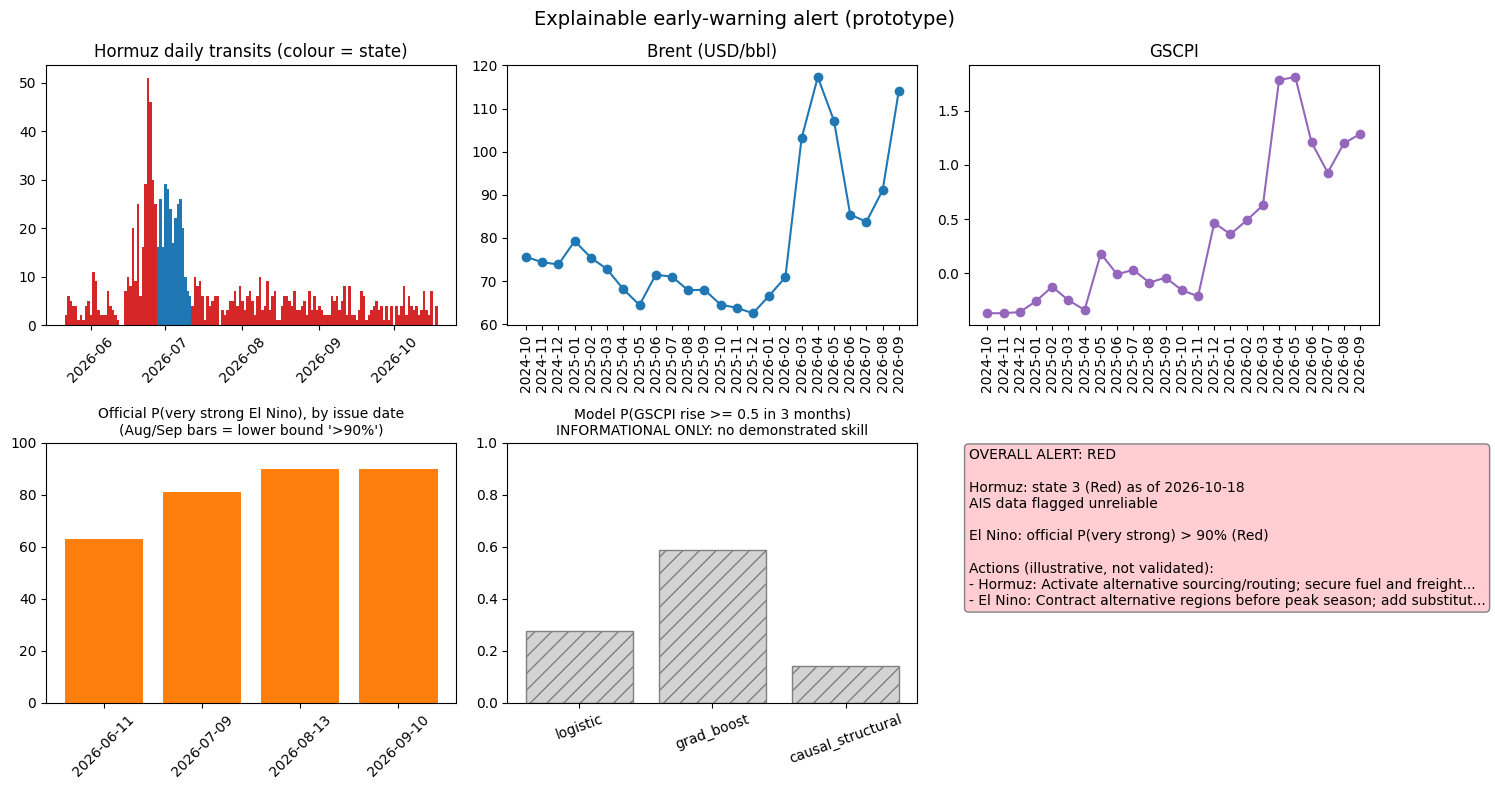

In [7]:
LEVELS = ["Green", "Yellow", "Orange", "Red"]
def hormuz_level(state): return {0: 0, 1: 1, 2: 2, 3: 3, 4: 2}.get(int(state), 1)
def enso_level(p): return 3 if p >= 80 else 2 if p >= 50 else 1 if p >= 20 else 0
protocol = pd.DataFrame([
 ["Hormuz", "Green (state 0)", "Routine monitoring; confirm alternative routes and contracts exist"],
 ["Hormuz", "Yellow (state 1)", "Review route dependency; check inventory cover of fuel- and petrochemical-linked inputs"],
 ["Hormuz", "Orange (state 2 or 4)", "Pre-book alternative routing; raise safety stock for energy-intensive inputs; daily monitoring"],
 ["Hormuz", "Red (state 3)", "Activate alternative sourcing/routing; secure fuel and freight contracts; escalate to crisis team"],
 ["El Nino", "Green (<20% strong-event probability)", "Routine seasonal review"],
 ["El Nino", "Yellow (20-49%)", "Map supplier regions and crops at risk; request supplier water/power contingency plans"],
 ["El Nino", "Orange (50-79%)", "Dual-source climate-sensitive materials (e.g., cotton) across regions; build seasonal buffer"],
 ["El Nino", "Red (>=80%)", "Contract alternative regions before peak season; add substitute materials; review transport and water exposure"]],
 columns=["module", "alert_level", "management_action"])
protocol.to_csv(f"{BASE}/table_decision_protocol.csv", index=False); print(protocol.to_string(index=False))
print("NOTE: this protocol is illustrative and is NOT validated; it needs firm-level cost data.")

daily = pd.read_csv(f"{BASE}/hormuz_daily_state.csv", parse_dates=["date"]).set_index("date")
last_state = int(daily["state"].dropna().iloc[-1]); last_day = daily.index[-1]
p_vs = float(vint.loc[vint.issue_date == "2026-09-10", "p_very_strong"].iloc[0])
lv = max(hormuz_level(last_state), enso_level(p_vs))
# informational model risk at the latest origin (models have NO demonstrated skill)
trn = panel.index[yv.reindex(panel.index).notna().values]
m1 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(panel.loc[trn, FEATS], yv.loc[trn])
m2 = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=0).fit(panel.loc[trn, FEATS], yv.loc[trn])
xl = panel.loc[[pd.Period("2026-09", freq="M")], FEATS]
best_now, _ = simulate(r0, 3)
risk = {"logistic": float(m1.predict_proba(xl)[:, 1][0]), "grad_boost": float(m2.predict_proba(xl)[:, 1][0]), "causal_structural": float((best_now >= 0.5).mean())}
alert = pd.DataFrame([dict(as_of=str(last_day.date()), hormuz_state=last_state, hormuz_level=LEVELS[hormuz_level(last_state)], ais_unreliable=int(daily["ais_unreliable"].iloc[-1]),
                           enso_p_very_strong_official=p_vs, enso_level=LEVELS[enso_level(p_vs)], overall_alert=LEVELS[lv], **{f"risk_{k}": round(v, 3) for k, v in risk.items()})])
print(alert.T.to_string()); alert.to_csv(f"{BASE}/latest_alert.csv", index=False)

fig, axs = plt.subplots(2, 3, figsize=(15, 8)); colors = {0: "tab:green", 1: "gold", 2: "orange", 3: "tab:red", 4: "tab:blue"}
dd_ = daily.iloc[-150:]; axs[0, 0].bar(dd_.index, dd_["n_total"], color=[colors.get(int(s), "grey") if pd.notna(s) else "grey" for s in dd_["state"]], width=1.0)
axs[0, 0].set_title("Hormuz daily transits (colour = state)"); axs[0, 0].tick_params(axis="x", rotation=45)
axs[0, 1].plot([str(m) for m in panel.index[-24:]], panel["brent"].iloc[-24:], "o-"); axs[0, 1].set_title("Brent (USD/bbl)"); axs[0, 1].tick_params(axis="x", rotation=90)
axs[0, 2].plot([str(m) for m in panel.index[-24:]], panel["gscpi"].iloc[-24:], "o-", color="tab:purple"); axs[0, 2].set_title("GSCPI"); axs[0, 2].tick_params(axis="x", rotation=90)
v2 = vint.dropna(subset=["p_very_strong"]); axs[1, 0].bar(v2.issue_date, v2.p_very_strong, color="tab:orange"); axs[1, 0].set_ylim(0, 100)
axs[1, 0].set_title("Official P(very strong El Nino), by issue date\n(Aug/Sep bars = lower bound '>90%')", fontsize=10); axs[1, 0].tick_params(axis="x", rotation=45)
axs[1, 1].bar(list(risk), list(risk.values()), color="lightgrey", hatch="//", edgecolor="grey"); axs[1, 1].set_ylim(0, 1)
axs[1, 1].set_title("Model P(GSCPI rise >= 0.5 in 3 months)\nINFORMATIONAL ONLY: no demonstrated skill", fontsize=10); axs[1, 1].tick_params(axis="x", rotation=20)
axs[1, 2].axis("off"); box = {"Green": "#c8e6c9", "Yellow": "#fff9c4", "Orange": "#ffe0b2", "Red": "#ffcdd2"}[LEVELS[lv]]
txt = (f"OVERALL ALERT: {LEVELS[lv].upper()}\n\nHormuz: state {last_state} ({LEVELS[hormuz_level(last_state)]}) as of {last_day.date()}\nAIS data flagged unreliable\n\n"
       f"El Nino: official P(very strong) > {int(p_vs)}% ({LEVELS[enso_level(p_vs)]})\n\nActions (illustrative, not validated):\n- Hormuz: {protocol.iloc[3,2][:62]}...\n- El Nino: {protocol.iloc[7,2][:62]}...")
axs[1, 2].text(0.0, 0.98, txt, va="top", fontsize=10, bbox=dict(boxstyle="round", fc=box, ec="grey"), wrap=True)
fig.suptitle("Explainable early-warning alert (prototype)", fontsize=14); fig.tight_layout(); fig.savefig(f"{BASE}/fig_alert_dashboard.png", dpi=150); plt.show()

## 7. Comparison table (section 15) and compliance audit (section 16)

In [8]:
def rd(name):
    f = f"{BASE}/{name}"; return pd.read_csv(f) if os.path.exists(f) else None
ev = rd("event_inference.csv"); pr = rd("primary_results.csv")
def evtxt(series):
    if ev is None: return "run Step 5"
    r = ev[(ev.window_months == 1) & (ev.series == series)].iloc[0]; return f"1-month change {r.value} (z = {r.z}, {r.hist_percentile} percentile of history)"
def fctxt(target):
    if pr is None: return "run Step 5"
    r = pr[pr.target == target].sort_values("auc", ascending=False).iloc[0]; return f"best model {r.model}: AUC {r.auc} {r.auc_ci95}, Brier skill {r.brier_skill}"
comp_tab = pd.DataFrame({
 "Dimension": ["External driver", "Shock/forecast state", "Main mediators in our data", "Timescale", "Observed outcome change after onset", "Out-of-sample warning evidence (h=3)",
               "Key data gap", "Management action (illustrative)", "Main uncertainty"],
 "Hormuz (geopolitical)": ["Security incident, traffic collapse", "States 0-4 from AIS transit throughput", "Transit calls, Brent", "Days to weeks (sudden)",
                           evtxt("Brent log change") + "; " + evtxt("GSCPI change"), "One episode only: not trainable; " + fctxt("Brent rise >= 10%"),
                           "Route dependency, alternative routes, inventory; AIS gaps", "Alternative routing/sourcing, fuel and freight contracts", "AIS reliability; cause of traffic drop cannot be separated from other shocks"],
 "El Nino (environmental)": ["ENSO warming (ONI/RONI, Nino-3.4)", "Official forecast probabilities (vintages)", "None observed (needs rainfall, drought, crop yield, cotton price)", "Months to seasons (slow)",
                            f"6m after onset: GSCPI {ct_g['mean_change_6m_after_onset']:+.2f} (p = {ct_g['p_two_sided']}; {ct_g['mean_excluding_covid_episode']:+.2f} without the COVID-overlap episode); Brent {ct_b['mean_change_6m_after_onset']:+.2f} (p = {ct_b['p_two_sided']})",
                            "ENSO features add no out-of-sample skill (ablation, Step 4)", "Regional weather, crop and commodity data", "Dual-source climate-sensitive materials; seasonal buffer", "Impacts are regional and not guaranteed even in strong events"]})
print(comp_tab.to_string(index=False)); comp_tab.to_csv(f"{BASE}/table_comparison_hormuz_elnino.csv", index=False)

audit = pd.DataFrame([
 ["Hormuz treated as a changing risk state", "Done", "States 0-4, threshold sensitivity", "State 1 still needs manual coding from JMIC/IMO"],
 ["El Nino treated as probabilistic climate driver", "Done", "table_elnino_2026_vintages.csv", "8 Oct 2026 vintage not retrieved; Mar and Jun rows need CPC-archive check"],
 ["Every 2026 fact has date and authoritative source", "Partial", "Vintage table; data dictionary access dates", "Hormuz event facts need dated primary sources"],
 ["Future information not used for earlier conditions", "Done", f"Leakage audit: {bad} mismatches", "Forecast vintages are not yet used as model inputs"],
 ["Regional weather and commodity exposure in El Nino analysis", "MISSING", "-", "Needs regional rainfall/drought, crop yield and cotton price data"],
 ["Route dependency and alternative routes in Hormuz analysis", "MISSING", "-", "Needs trade-route shares (Comtrade/EIA) or firm data"],
 ["Confounders and mediators separated", "Done", "causal_dag.png, causal_assumptions.csv", "Confounders are unobserved"],
 ["Feature importance not presented as causal proof", "Done", "Explanation notes in outputs", "Keep this wording in the paper"],
 ["Comparable final outcomes for both cases", "Done", "GSCPI and Brent targets", "Global proxies"],
 ["Every warning leads to a specific action", "Partial", "table_decision_protocol.csv", "Protocol is illustrative and not validated"],
 ["Calibration, lead time, false alarms, stability reported", "Done", "Steps 4 and 5; table_explanation_stability.csv", "Results show no demonstrated skill"]],
 columns=["Section 16 checklist item", "Status", "Evidence", "Remaining gap"])
print(audit.to_string(index=False)); audit.to_csv(f"{BASE}/table_compliance_audit.csv", index=False)

                           Dimension                                                                                                  Hormuz (geopolitical)                                                                                   El Nino (environmental)
                     External driver                                                                                    Security incident, traffic collapse                                                                         ENSO warming (ONI/RONI, Nino-3.4)
                Shock/forecast state                                                                                 States 0-4 from AIS transit throughput                                                                Official forecast probabilities (vintages)
          Main mediators in our data                                                                                                   Transit calls, Brent                                         None observed (nee